# Delete takeoffs and landings
Author: Brian Green (briangre@stanford.edu)

In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import netCDF4 as nc

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()

%matplotlib inline

DZ_THRESH = 500 # (m) the balloon must be within this distance of its cruising altitude after
                #     takeoff and before landing for the data to be included
ALT_THRESH = 10000 # (m) the threshold to determine whether the balloon data has a takeoff or landing

In [2]:
# Load in the data
flights = pd.read_feather('Concordiasi_with_ERA5.feather')

01 2010-09-23 01:18:30
02 2010-09-23 05:06:30
03 2010-10-15 05:21:00
04 2010-09-24 01:21:30
05 2010-09-25 04:02:30
06 2010-09-29 00:00:30
07 2010-09-30 03:11:30
08 2010-10-26 12:37:00
09 2010-10-07 22:40:00
10 2010-10-14 22:49:30
11 2010-10-19 05:57:00
12 2010-10-20 22:29:30
13 2010-10-19 08:54:00
14 2010-09-15 04:09:30
15 2010-09-08 22:10:30
16 2010-09-11 03:32:30
17 2010-09-14 02:46:30
18 2010-09-29 03:52:00
19 2010-10-08 03:19:30


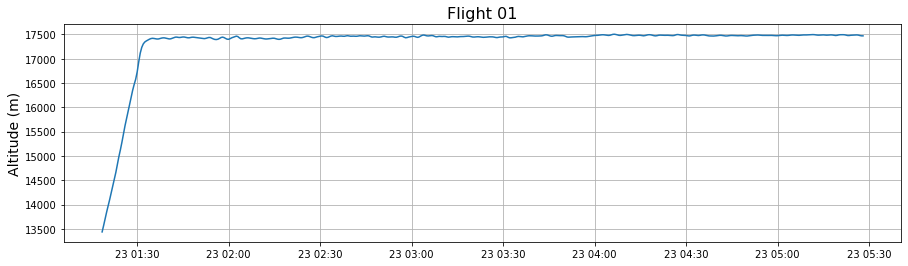

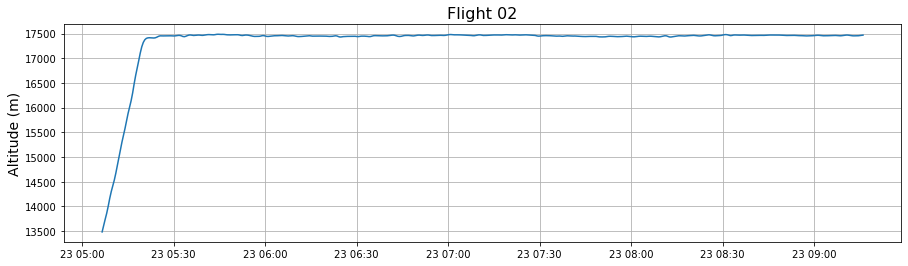

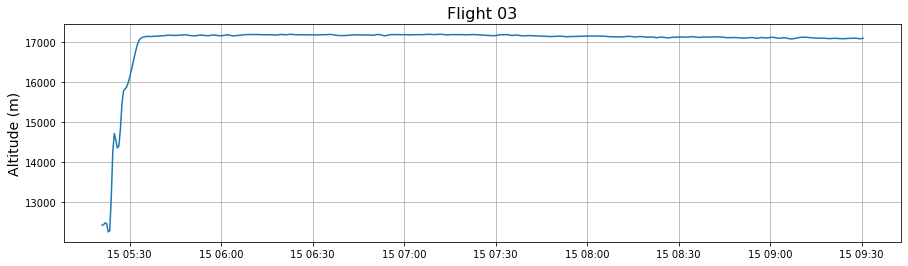

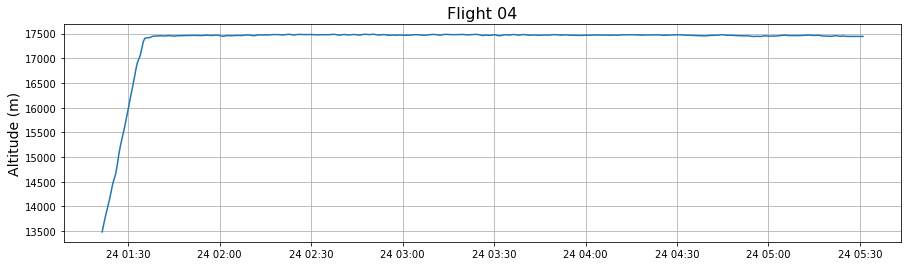

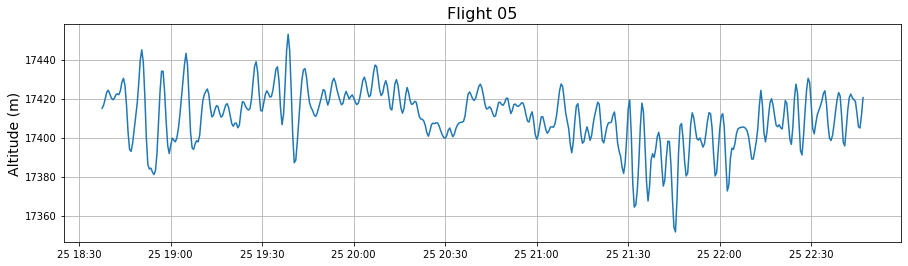

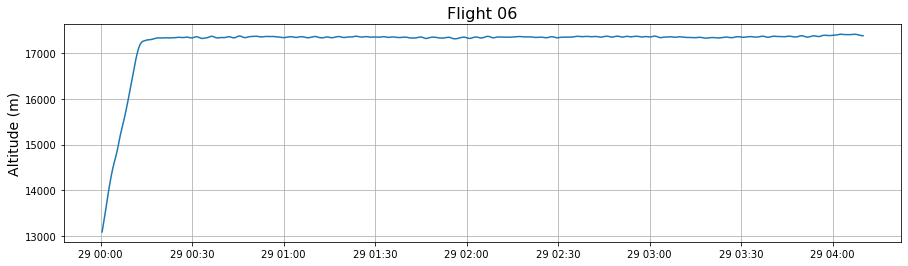

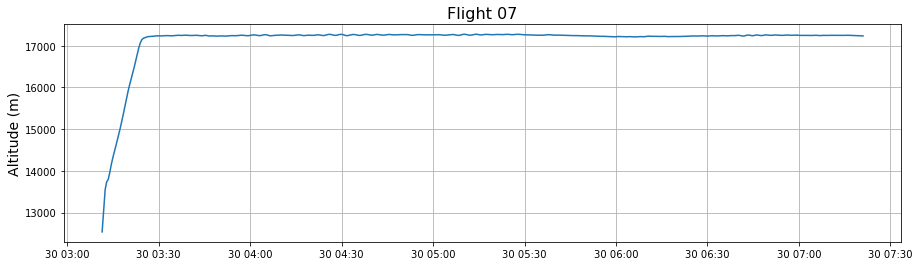

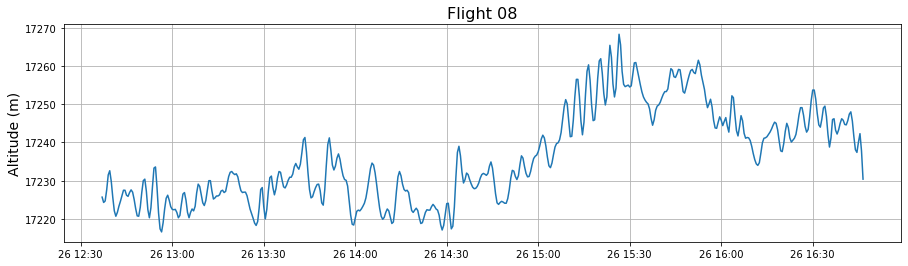

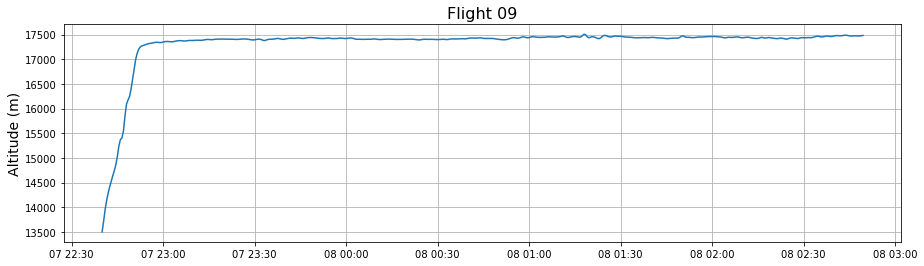

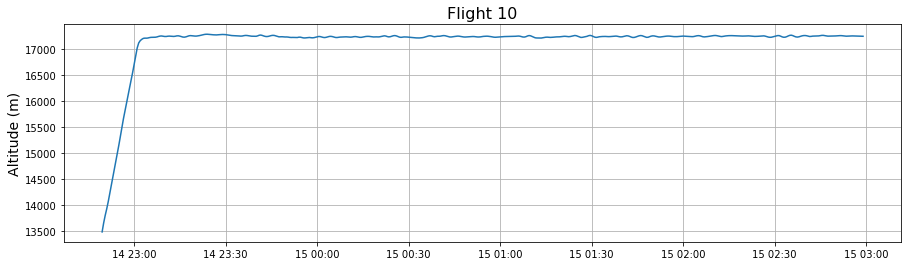

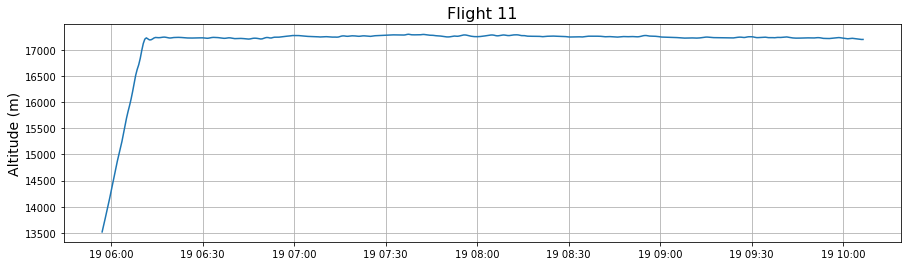

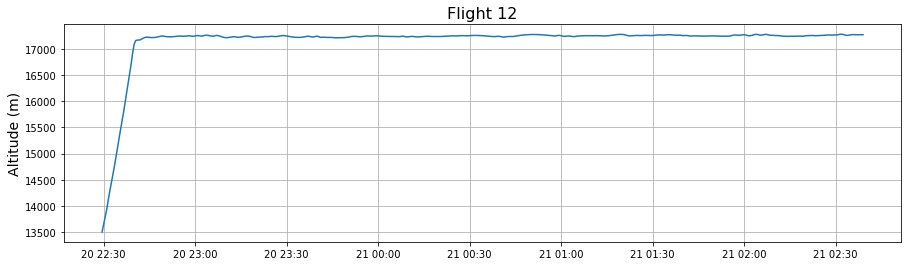

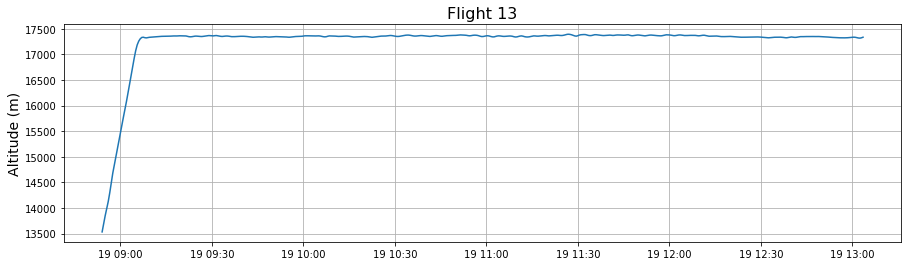

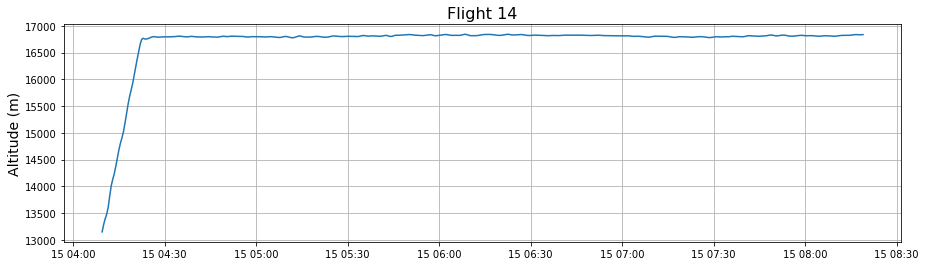

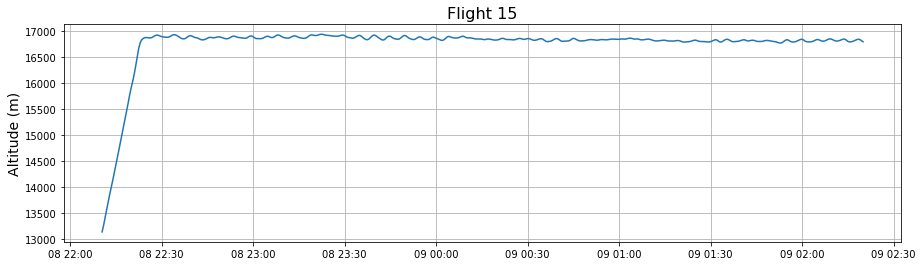

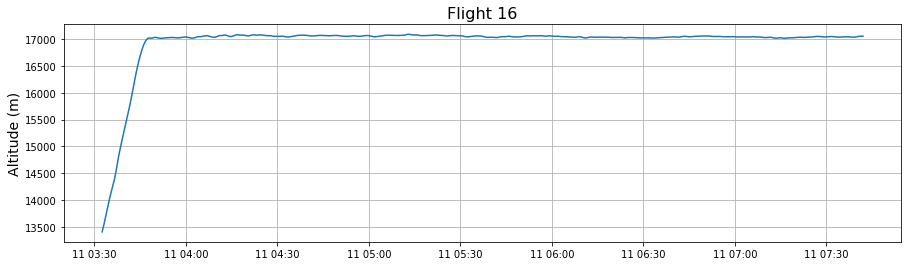

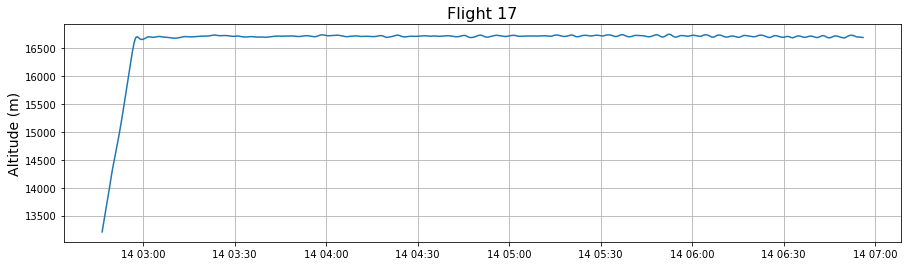

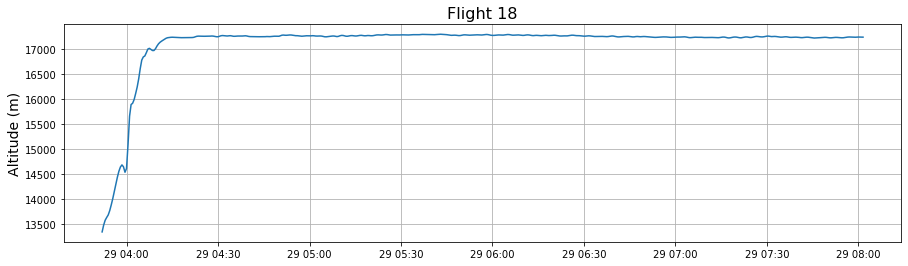

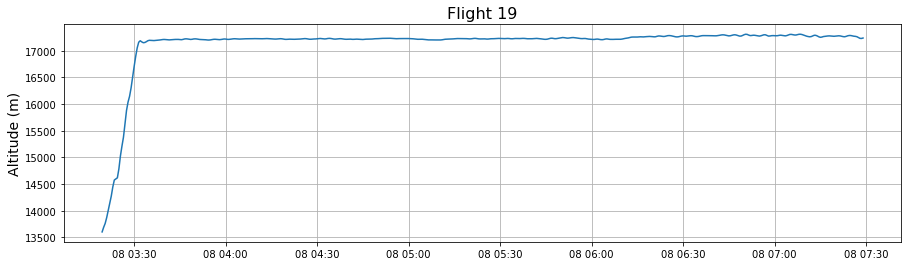

In [3]:
# Plot the beginning of each flight
flight_ids = flights.flight_id.unique()
n_flights = flight_ids.size

for i in np.arange(n_flights):
    
    flight = flights[flights.flight_id == flight_ids[i]].copy()
    print(flight_ids[i], flight.time.iloc[0])
    ind_start = 0
    if flight_ids[i] == '05':
        ind_start = 1750
    
    plt.figure(figsize=(15,4))
    plt.plot(flight.time[ind_start:ind_start+500],flight.altitude[ind_start:ind_start+500])
    plt.grid()
    plt.title(f'Flight {flight_ids[i]}', fontsize=16)
    plt.ylabel('Altitude (m)', fontsize=14);
    
start_time = np.array([pd.Timestamp('2010-09-23 01:35:00'),
                       pd.Timestamp('2010-09-23 05:25:00'),
                       pd.Timestamp('2010-10-15 05:35:00'),
                       pd.Timestamp('2010-09-24 01:40:00'),
                       pd.Timestamp('2010-09-25 04:30:00'),
                       pd.Timestamp('2010-09-29 00:15:00'),
                       pd.Timestamp('2010-09-30 03:30:00'),
                       pd.Timestamp('2010-10-26 12:30:00'),
                       pd.Timestamp('2010-10-07 22:55:00'),
                       pd.Timestamp('2010-10-14 23:05:00'),
                       pd.Timestamp('2010-10-19 06:15:00'),
                       pd.Timestamp('2010-10-20 22:45:00'),
                       pd.Timestamp('2010-10-19 09:10:00'),
                       pd.Timestamp('2010-09-15 04:30:00'),
                       pd.Timestamp('2010-09-08 22:25:00'),
                       pd.Timestamp('2010-09-11 03:50:00'),
                       pd.Timestamp('2010-09-14 03:00:00'),
                       pd.Timestamp('2010-09-29 04:15:00'),
                       pd.Timestamp('2010-10-08 03:40:00')])

# Trim off any takeoffs
flights_no_takeoffs = pd.DataFrame(columns = flights.columns)
for i in np.arange(n_flights):
    flight = flights[flights.flight_id == flight_ids[i]].copy()
    flight = flight[flight.time >= start_time[i]]
    flights_no_takeoffs = flights_no_takeoffs.append(flight, ignore_index=True)

01 2010-12-11 00:58:00
02 2010-11-18 15:31:30
03 2010-10-31 20:24:00
04 2010-12-27 10:14:00
05 2010-10-02 18:42:00
06 2010-12-09 16:05:00
07 2010-12-09 11:24:30
08 2010-11-19 19:23:00
09 2010-10-09 01:59:00
10 2010-12-24 08:21:00
11 2010-12-29 17:35:00
12 2011-01-23 17:19:00
13 2010-11-30 04:00:00
14 2010-12-21 14:14:30
15 2010-09-14 14:21:00
16 2010-10-04 05:49:30
17 2010-10-15 04:29:30
18 2010-11-30 07:05:30
19 2010-11-23 09:58:30


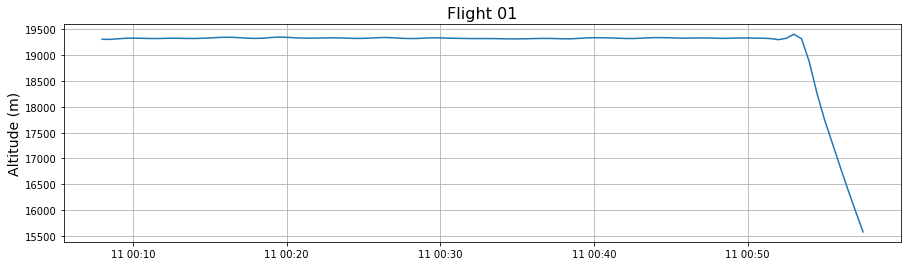

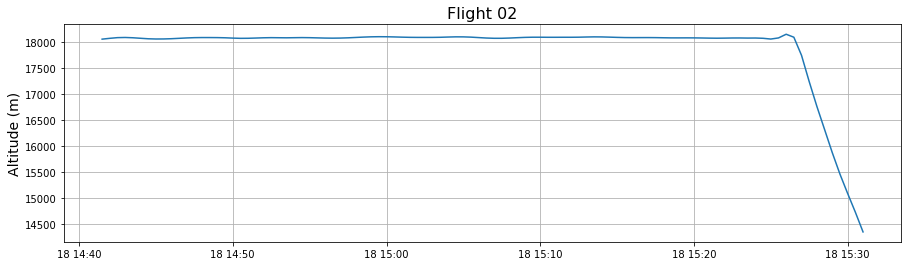

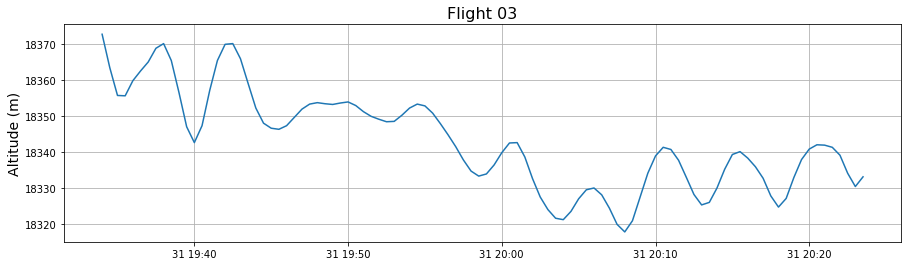

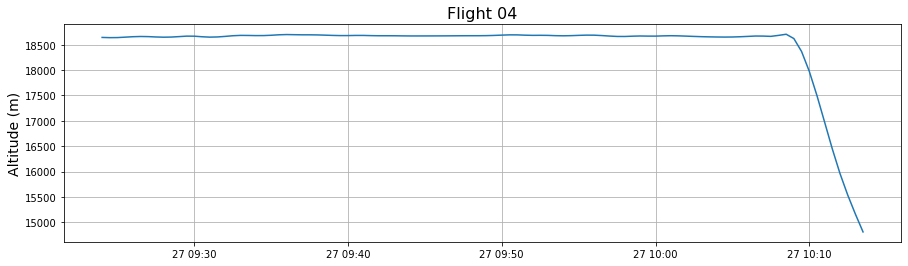

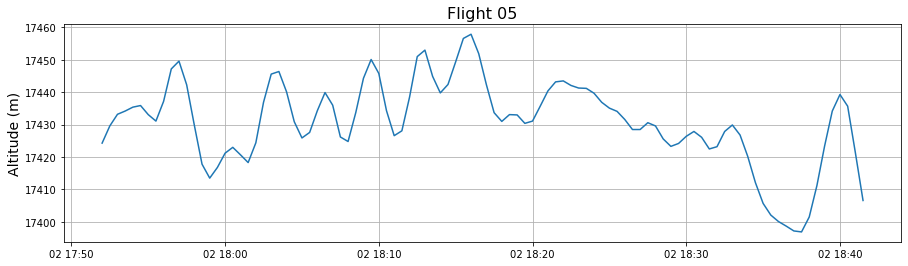

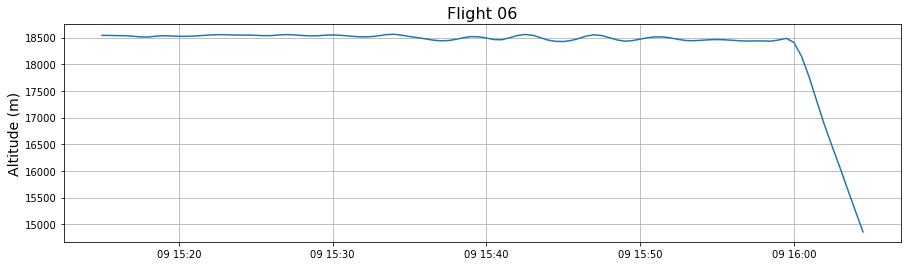

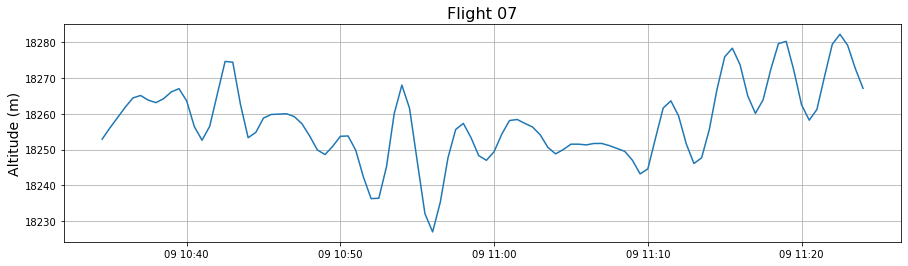

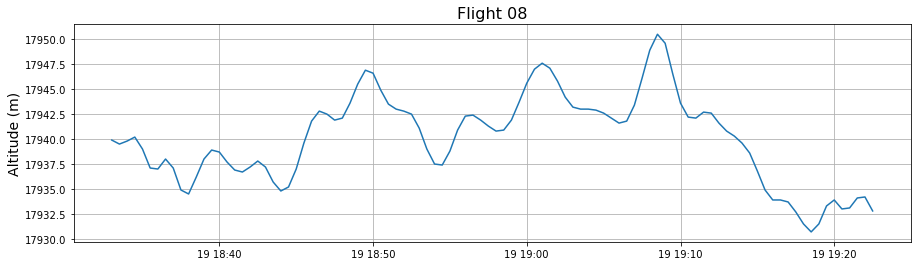

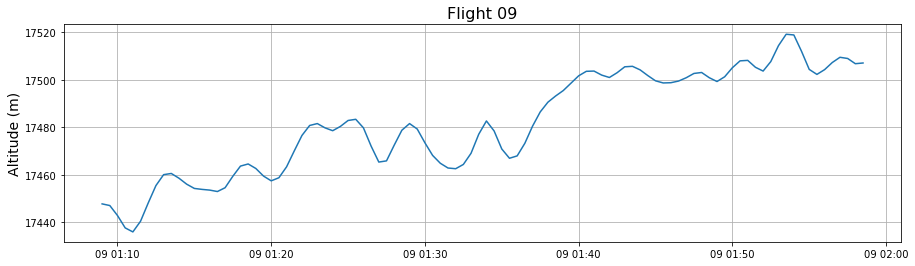

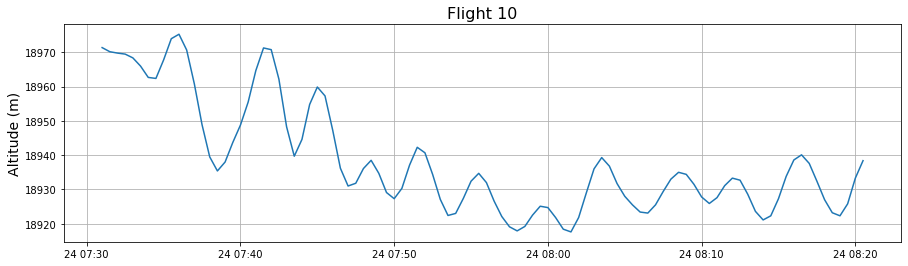

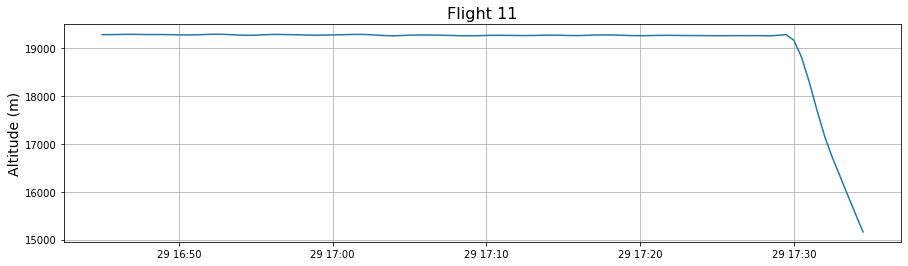

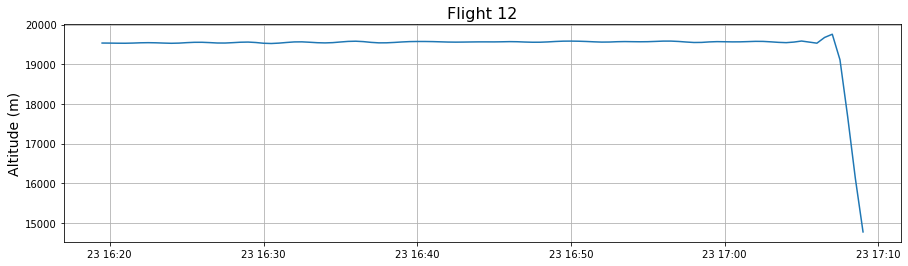

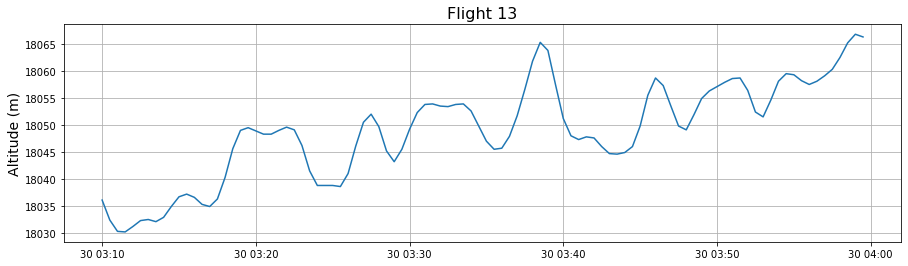

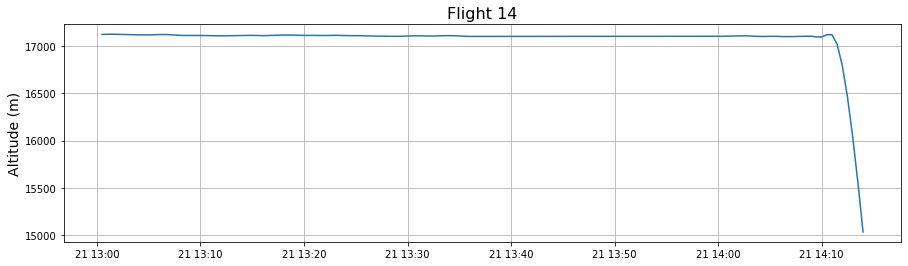

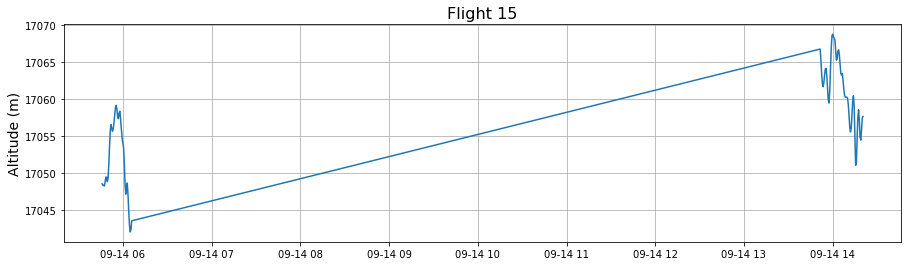

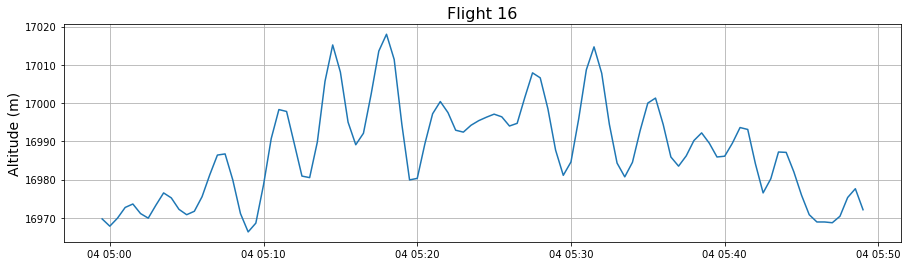

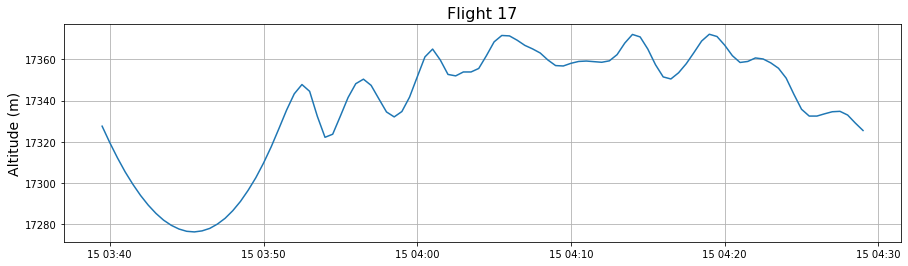

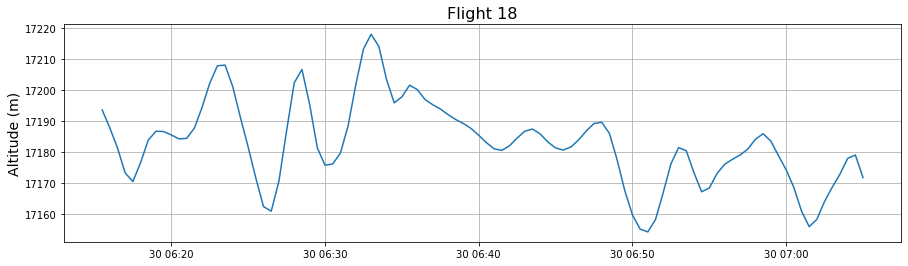

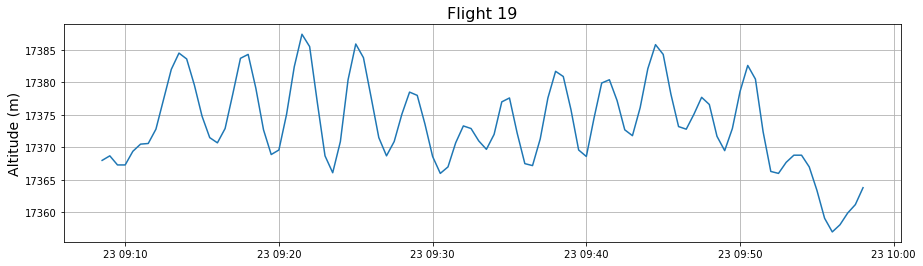

In [4]:
# Plot the ending of each flight
for i in np.arange(n_flights):
    
    flight = flights[flights.flight_id == flight_ids[i]].copy()
    print(flight_ids[i], flight.time.iloc[-1])
    ind_stop = -1
    
    plt.figure(figsize=(15,4))
    plt.plot(flight.time[ind_stop-100:ind_stop],flight.altitude[ind_stop-100:ind_stop])
    plt.grid()
    plt.title(f'Flight {flight_ids[i]}', fontsize=16)
    plt.ylabel('Altitude (m)', fontsize=14);
    
stop_time = np.array([pd.Timestamp('2010-12-11 00:50:00'),
                      pd.Timestamp('2010-11-18 15:25:00'),
                      pd.Timestamp('2010-10-31 20:25:00'),
                      pd.Timestamp('2010-12-27 10:05:00'),
                      pd.Timestamp('2010-10-02 18:43:00'),
                      pd.Timestamp('2010-12-09 15:55:00'),
                      pd.Timestamp('2010-12-09 11:25:30'),
                      pd.Timestamp('2010-11-19 19:24:00'),
                      pd.Timestamp('2010-10-09 02:00:00'),
                      pd.Timestamp('2010-12-24 08:22:00'),
                      pd.Timestamp('2010-12-29 17:25:00'),
                      pd.Timestamp('2011-01-23 17:05:00'),
                      pd.Timestamp('2010-11-30 04:01:00'),
                      pd.Timestamp('2010-12-21 14:10:00'),
                      pd.Timestamp('2010-09-14 14:22:00'),
                      pd.Timestamp('2010-10-04 05:50:30'),
                      pd.Timestamp('2010-10-15 04:30:30'),
                      pd.Timestamp('2010-11-30 07:06:30'),
                      pd.Timestamp('2010-11-23 09:59:30')])

# Trim off any landings
flights_no_takeoffs_or_landings = pd.DataFrame(columns = flights.columns)
for i in np.arange(n_flights):
    flight = flights_no_takeoffs[flights_no_takeoffs.flight_id == flight_ids[i]].copy()
    flight = flight[flight.time <= stop_time[i]]
    flights_no_takeoffs_or_landings = flights_no_takeoffs_or_landings.append(flight, ignore_index=True)

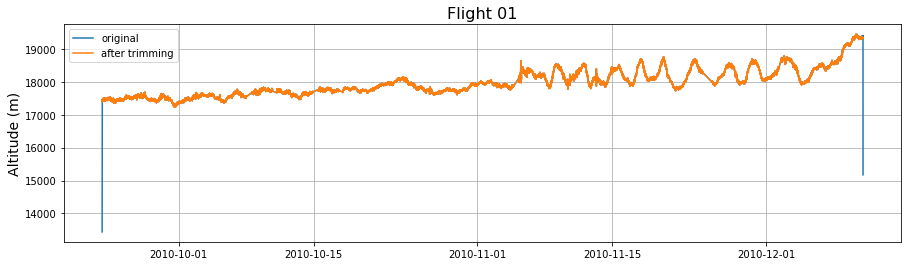

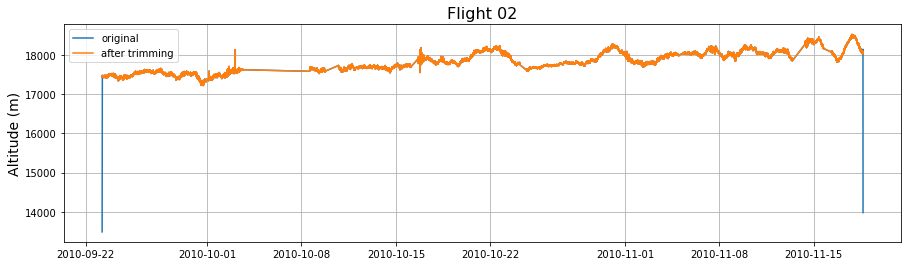

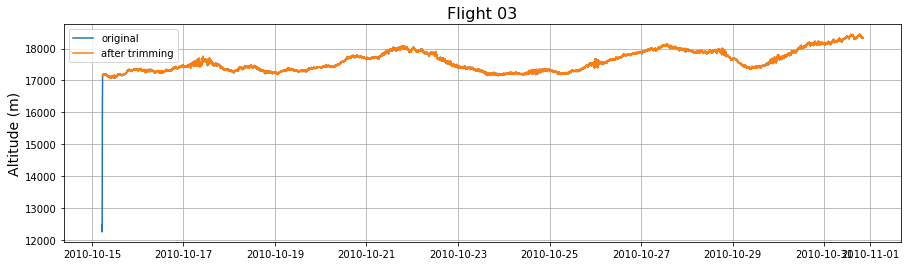

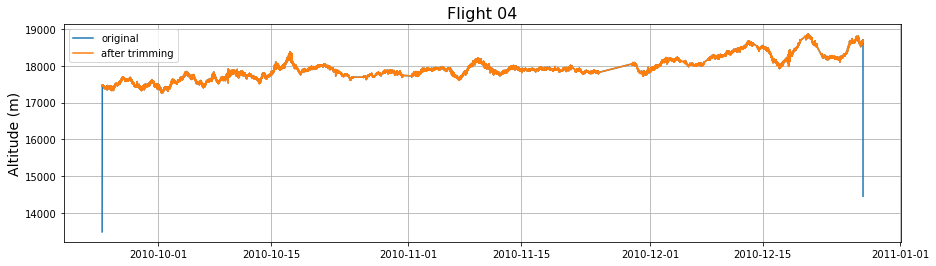

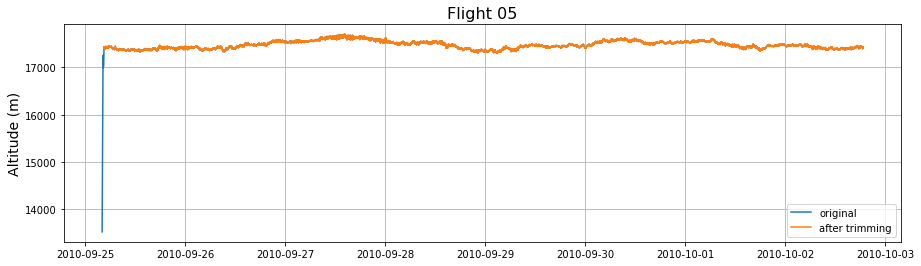

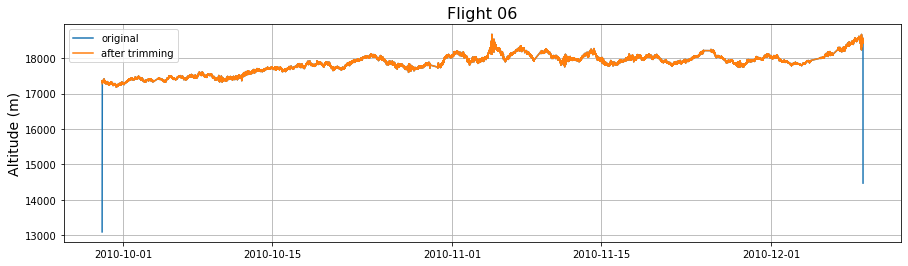

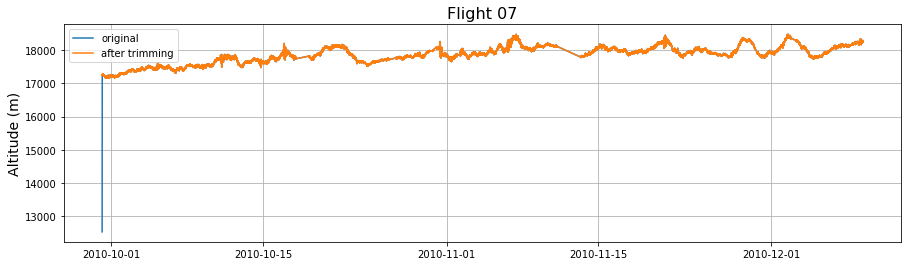

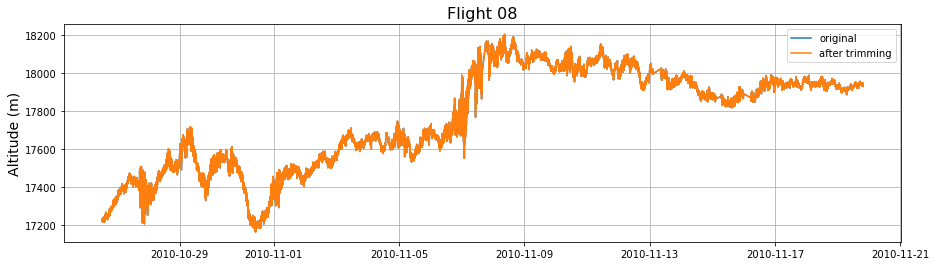

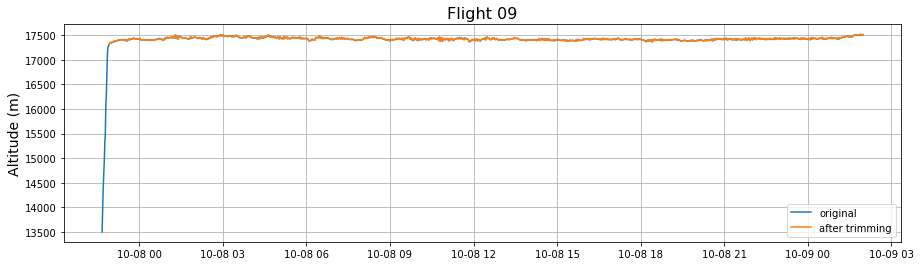

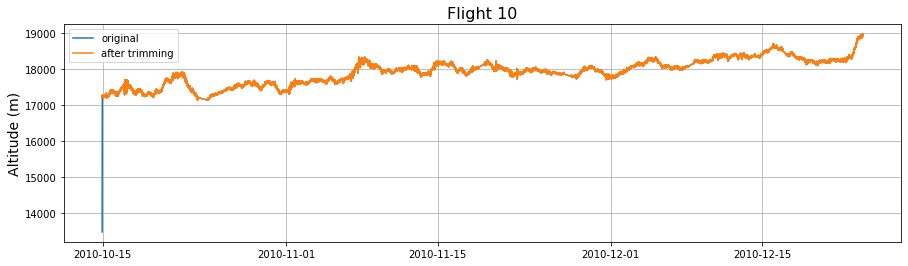

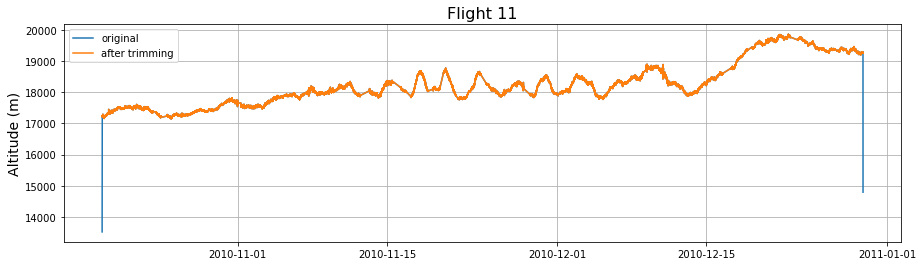

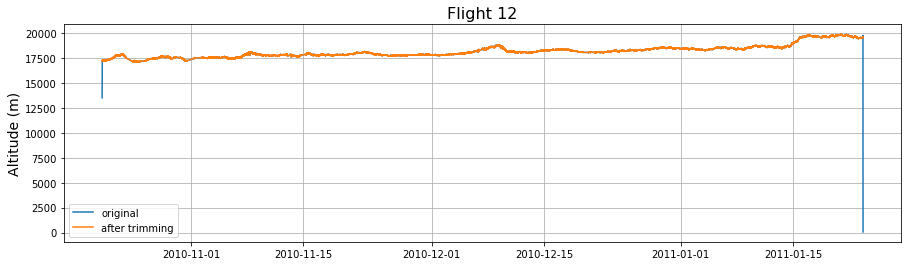

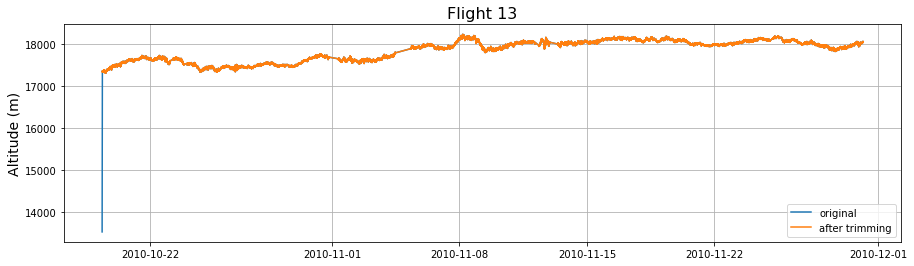

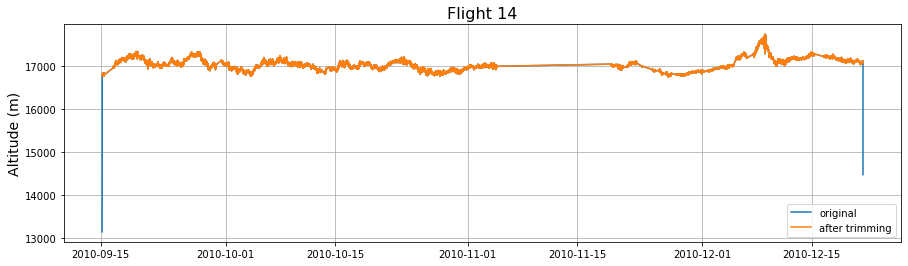

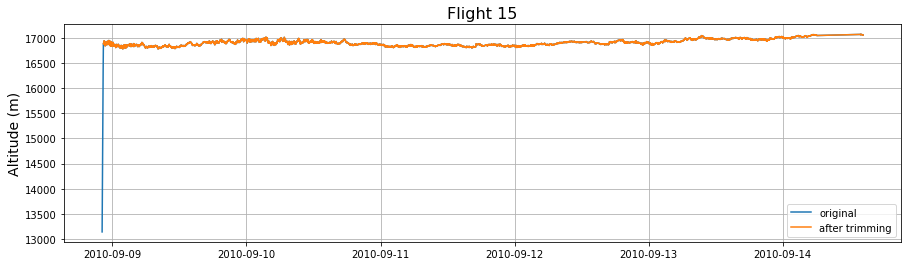

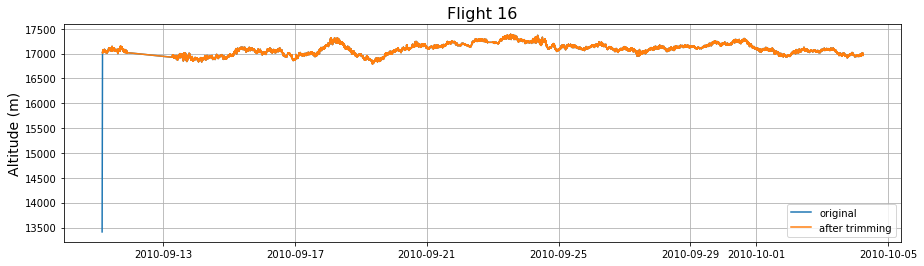

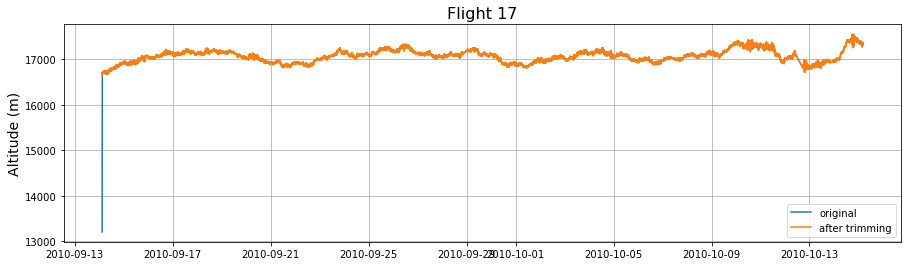

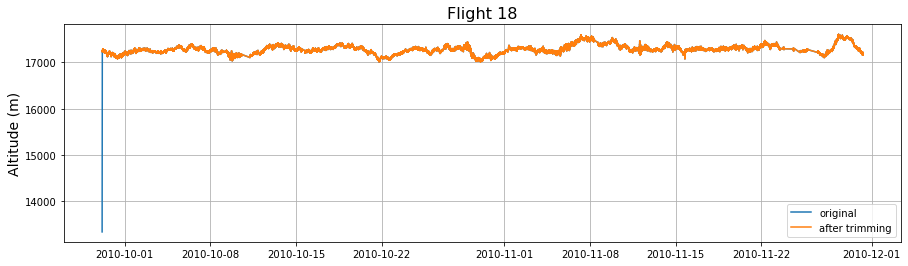

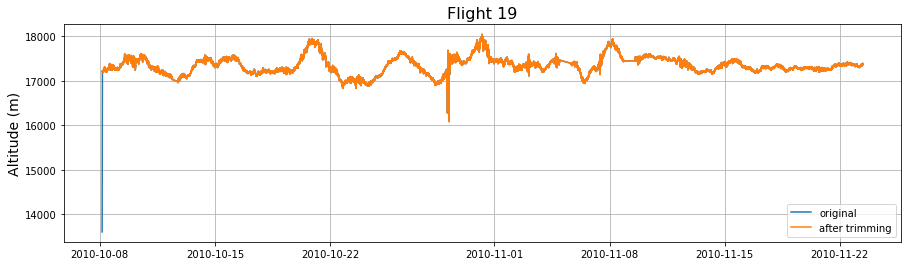

In [5]:
# Plot the before and after
for i in np.arange(n_flights):
    
    flight1 = flights[flights.flight_id == flight_ids[i]].copy()
    flight2 = flights_no_takeoffs_or_landings[flights_no_takeoffs_or_landings.flight_id == flight_ids[i]].copy()
    
    plt.figure(figsize=(15,4))
    plt.plot(flight1.time,flight1.altitude)
    plt.plot(flight2.time,flight2.altitude)
    plt.grid()
    plt.title(f'Flight {flight_ids[i]}', fontsize=16)
    plt.ylabel('Altitude (m)', fontsize=14)
    plt.legend(['original','after trimming']);

In [6]:
# Save the data
flights_no_takeoffs_or_landings.to_feather('Concordiasi_with_ERA5_2_takeoffs_landings.feather') 
flights_no_takeoffs_or_landings

,flight_id,time,latitude,longitude,altitude,u,v,pressure,T_ERA5,N2_ERA5,superpressure
0,01,2010-09-23 01:35:00,-78.406868,168.230804,17418.7,8.44,-9.58,61.573,192.615719,0.000580,7.54
1,01,2010-09-23 01:35:30,-78.409485,168.242310,17415.3,8.36,-9.75,61.616,192.613123,0.000580,7.70
2,01,2010-09-23 01:36:00,-78.412132,168.253815,17408.5,8.37,-9.82,61.715,192.607186,0.000579,7.83
3,01,2010-09-23 01:36:30,-78.414772,168.265289,17403.8,8.40,-9.79,61.751,192.605042,0.000579,7.97
4,01,2010-09-23 01:37:00,-78.417358,168.276642,17405.5,8.43,-9.68,61.691,192.608620,0.000579,8.11
...,...,...,...,...,...,...,...,...,...,...,...
2525765,19,2010-11-23 09:56:30,-76.329704,-20.570866,17358.1,10.33,6.50,66.584,207.932783,0.000660,11.60
2525766,19,2010-11-23 09:57:00,-76.327957,-20.559189,17359.9,10.30,6.47,66.571,207.936609,0.000660,11.62
2525767,19,2010-11-23 09:57:30,-76.326241,-20.547585,17361.2,10.28,6.44,66.583,207.933077,0.000660,11.63
2525768,19,2010-11-23 09:58:00,-76.324539,-20.535913,17363.8,10.27,6.41,66.555,207.941321,0.000660,11.65
